# MODEL: VGG16
TASK : Crop Pest and Disease Detection - End-to-End Pipeline
Paste each CELL block into a separate cell in your Jupyter Notebook.
Run cells in order from top to bottom.

---


### Digital Image Processing Concepts Used in This Model

In digital image processing (DIP) for plant pathology, diagnosing foliar crop diseases relies on detecting localized color changes, edge transitions, and spatial surface textures in digital leaf photographs. Pathogens cause tissue degradation that alters light absorption and reflection, resulting in distinctive chlorotic halos and necrotic lesions.

#### Why Crop Images Require Preprocessing
1. **Field Illumination Shifts:** Uncontrolled natural daylight introduces specular highlights, shadows, and varying color temperatures.
2. **Variable Capture Perspective:** Handheld and drone cameras capture leaves at diverse angles and distances, altering apparent symptom dimensions and orientation.
3. **Complex Agricultural Backgrounds:** Soil, dead organic mulch, and background foliage introduce non-target high-frequency spatial noise.
4. **Sensor Downsampling & Quantization:** Converting optical signals into digital matrices requires standardized spatial and radiometric normalization.

#### Spatial and Intensity Transformations in Training
- **Geometric Transformations:** Horizontal spatial reflection, affine rotation ($\pm 72^\circ$), and zoom scaling enforce rotational and viewpoint invariance.
- **Intensity Transformations:** Contrast adjustment simulates variable ambient illumination without changing lesion morphology.

#### VGG16: Hierarchical Feature Extraction via Stacked Small Kernels
VGG16 is a foundational, classical architecture composed of **homogeneous stacked $3 \times 3$ convolution filters** and **$2 \times 2$ max-pooling**. In digital image processing, it serves as a textbook demonstration of **receptive field enlargement**:
- Cascading two $3 \times 3$ convolution layers produces an effective spatial receptive field equivalent to a single $5 \times 5$ filter.
- Cascading three $3 \times 3$ convolutions achieves a $7 \times 7$ receptive field.

Using stacked $3 \times 3$ filters uses significantly fewer parameters ($3 \times 3^2 = 27$ weights vs. $7^2 = 49$ weights—a **$45\%$ parameter reduction**) while introducing intermediate non-linear activations after each filter.

#### End-to-End DIP & Classification Pipeline
$$\text{Input Image } (H \times W \times 3) \longrightarrow \text{Image Decoding \& Resizing } (224 \times 224) \longrightarrow \text{Data Augmentation } \longrightarrow \text{VGG16 Preprocessing (BGR + Mean Subtraction)} \longrightarrow \text{Stacked 3x3 Conv Blocks } \longrightarrow \text{Flatten \& Dense Head } \longrightarrow \text{Classification}$$

> **Important Case Study Note:** This model performs **whole-image classification** (predicting the disease category for the entire tile) rather than explicit **semantic pixel segmentation** (which would delineate exact boundary contours for each diseased lesion).

### CELL 1 ── Install Dependencies


In [21]:
!pip install -q split-folders scikit-learn seaborn matplotlib tensorflow

### CELL 2 ── Imports


In [2]:
import os
import warnings
import splitfolders
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, callbacks
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

c:\Users\tvija\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.21.0
GPU Available: []


### CELL 3 ── Verify & Load Local Dataset  (70 / 15 / 15)


In [3]:
# ==============================================================================
# DATASET PATH CONFIGURATION (Local Dataset in this folder)
# ==============================================================================
# The dataset is stored locally in this project directory.
# - 'Dataset_Split': contains pre-split train (70%), val (15%), and test (15%) sets
# - 'dataset': contains the raw unsplit 22 disease/pest class folders

def resolve_path(folder_name):
    """Resolve local dataset folder path in the project workspace."""
    candidates = [
        folder_name,
        os.path.join(os.getcwd(), folder_name),
        os.path.join(os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else ".", folder_name),
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return folder_name

SPLIT_DIR = resolve_path("Dataset_Split")
RAW_DIR   = resolve_path("dataset")

if os.path.exists(SPLIT_DIR):
    print(f"[OK] Using local split dataset from: '{SPLIT_DIR}'")
elif os.path.exists(RAW_DIR):
    print(f"[NOTE] 'Dataset_Split' not found. Splitting local dataset from: '{RAW_DIR}' (70/15/15)...")
    splitfolders.ratio(RAW_DIR, output=SPLIT_DIR, seed=42, ratio=(0.70, 0.15, 0.15), group_prefix=None)
    print("[OK] Split complete.")
else:
    raise FileNotFoundError(
        f"Dataset not found in this folder! Looked for '{SPLIT_DIR}' and '{RAW_DIR}'. "
        "Please ensure the dataset folder is located in the project directory."
    )

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "val")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

print(f"  --> Train path : {TRAIN_DIR}")
print(f"  --> Val path   : {VAL_DIR}")
print(f"  --> Test path  : {TEST_DIR}")


Dataset_Split already ready — skipping split step.


### DIP: Digital Image Representation, Decoding, and Spatial Resizing

#### Digital Color Image Representation
A digital color photograph is represented as a 3D numerical matrix of shape $(H \times W \times 3)$, where $H$ is the spatial height, $W$ is the spatial width, and 3 represents the primary color channels: **Red (R), Green (G), and Blue (B)**. Each pixel intensity is an 8-bit unsigned integer ($uint8$) with values spanning $[0, 255]$.

#### Image Decoding
Stored JPEG images are compressed using Discrete Cosine Transform (DCT) quantization. During input pipeline execution, TensorFlow decompresses raw binary bitstreams into uncompressed 3D arrays of numerical pixel intensities.

#### Image Resizing and Spatial Downsampling
Deep neural networks process data in batches, requiring fixed, standardized tensor dimensions ($B \times H \times W \times C$):
- **VGG16 Standard Resolution:** All input images are standardized to **$224 \times 224$ pixels**.
- **Batch Size Configuration:** VGG16 contains a very large parameter footprint ($138\text{M}$ total / $14.7\text{M}$ backbone, with a large Dense head following `layers.Flatten()`). To avoid GPU Out-of-Memory (OOM) errors, **`BATCH_SIZE = 16`** is used.
- **Resolution Loss:** Downsampling high-resolution images to $224 \times 224$ can suppress very fine early-stage micro-pustules.
- **Aspect Ratio Distortion:** Direct bilinear downsampling to a square without padding may stretch non-square camera frames.

### CELL 4 ── Hyper-parameters & Data Loaders


In [ ]:
BATCH_SIZE = 16      # VGG16 is heavier — reduce batch size if OOM
IMG_SIZE   = (224, 224)
EPOCHS     = 25
SEED       = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 17568 files belonging to 22 classes.
Found 3761 files belonging to 22 classes.
Found 3795 files belonging to 22 classes.
Classes (22): ['Cashew anthracnose', 'Cashew gumosis', 'Cashew healthy', 'Cashew leaf miner', 'Cashew red rust', 'Cassava bacterial blight', 'Cassava brown spot', 'Cassava green mite', 'Cassava healthy', 'Cassava mosaic', 'Maize fall armyworm', 'Maize grasshoper', 'Maize healthy', 'Maize leaf beetle', 'Maize leaf blight', 'Maize leaf spot', 'Maize streak virus', 'Tomato healthy', 'Tomato leaf blight', 'Tomato leaf curl', 'Tomato septoria leaf spot', 'Tomato verticulium wilt']


In [ ]:
# DIP VISUALIZATION: Original Image vs. Resized Model Input (224x224)
import glob
from PIL import Image

sample_search = glob.glob(os.path.join(TRAIN_DIR, "*", "*.jpg"))
if sample_search:
    sample_file_path = sample_search[0]
    class_folder_name = os.path.basename(os.path.dirname(sample_file_path))
    
    orig_img = Image.open(sample_file_path)
    orig_w, orig_h = orig_img.size
    resized_img = orig_img.resize(IMG_SIZE, Image.BILINEAR)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f"DIP Spatial Resizing Analysis: {class_folder_name}", fontsize=14, fontweight="bold")
    
    axes[0].imshow(orig_img)
    axes[0].set_title(f"Original Acquisition\nDimensions: {orig_h} × {orig_w} × 3\nTotal Pixels: {orig_h * orig_w:,}", fontsize=11)
    axes[0].axis("on"); axes[0].tick_params(labelsize=8)
    
    axes[1].imshow(resized_img)
    axes[1].set_title(f"Resized VGG16 Input\nDimensions: {IMG_SIZE[1]} × {IMG_SIZE[0]} × 3\nTotal Pixels: {IMG_SIZE[0] * IMG_SIZE[1]:,}", fontsize=11)
    axes[1].axis("on"); axes[1].tick_params(labelsize=8)
    
    plt.tight_layout()
    plt.show()
    print(f"Spatial reduction ratio: {(orig_h * orig_w) / (IMG_SIZE[0] * IMG_SIZE[1]):.2f}x fewer pixels.")
else:
    print("No images found for resizing demonstration.")

### CELL 5 ── Explore: Sample Images


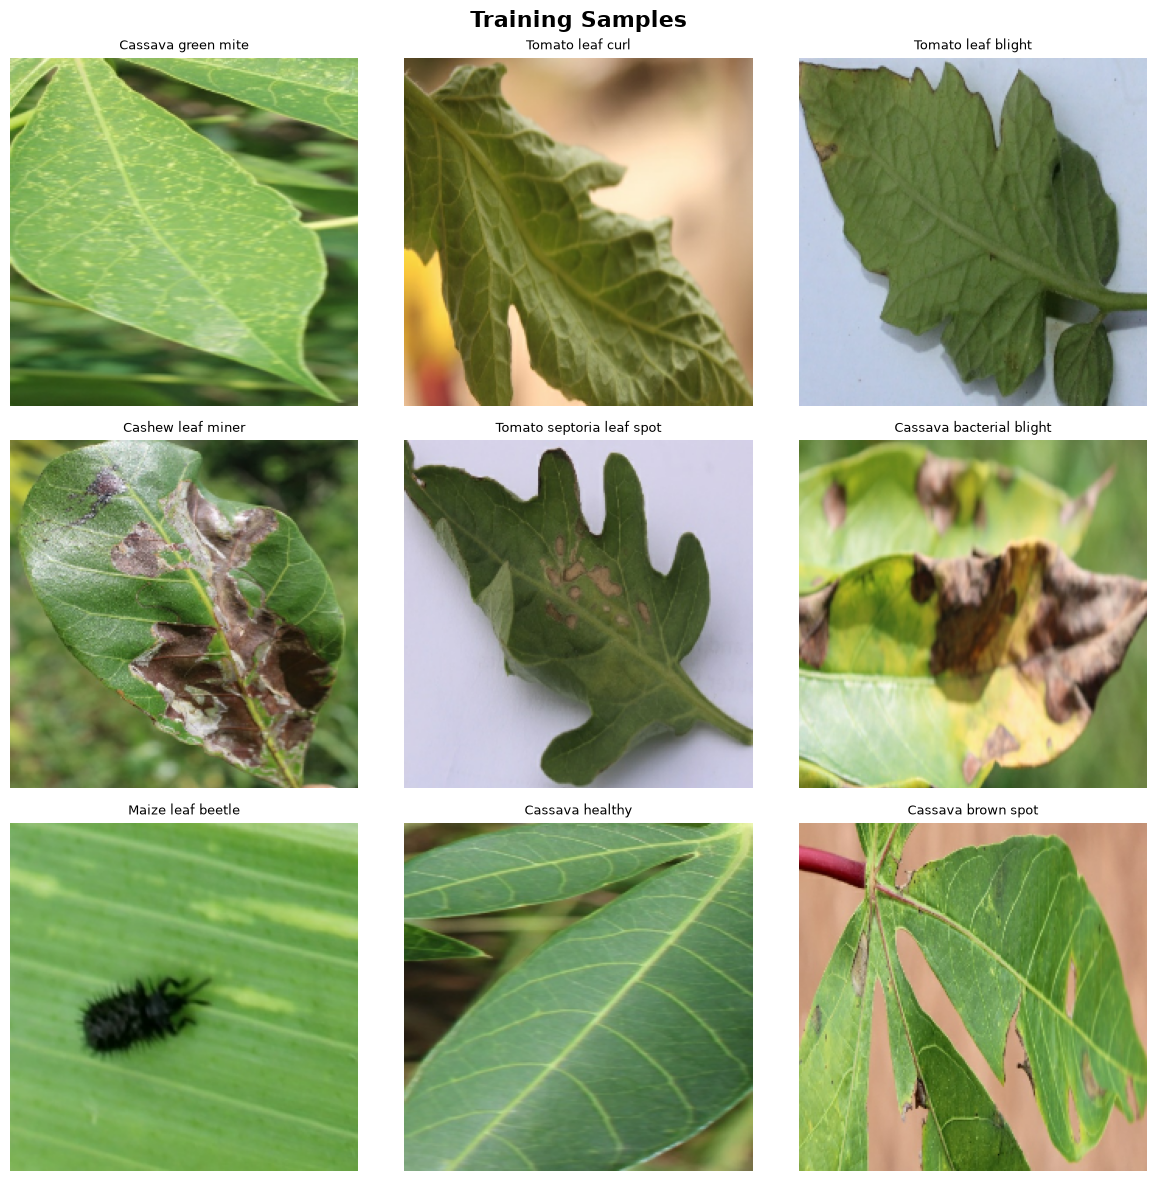

In [9]:
plt.figure(figsize=(12, 12))
plt.suptitle("Training Samples", fontsize=16, fontweight="bold")
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[labels[i]], fontsize=9)
        plt.axis("off")
plt.tight_layout(); plt.show()

### CELL 6 ── Class Distribution


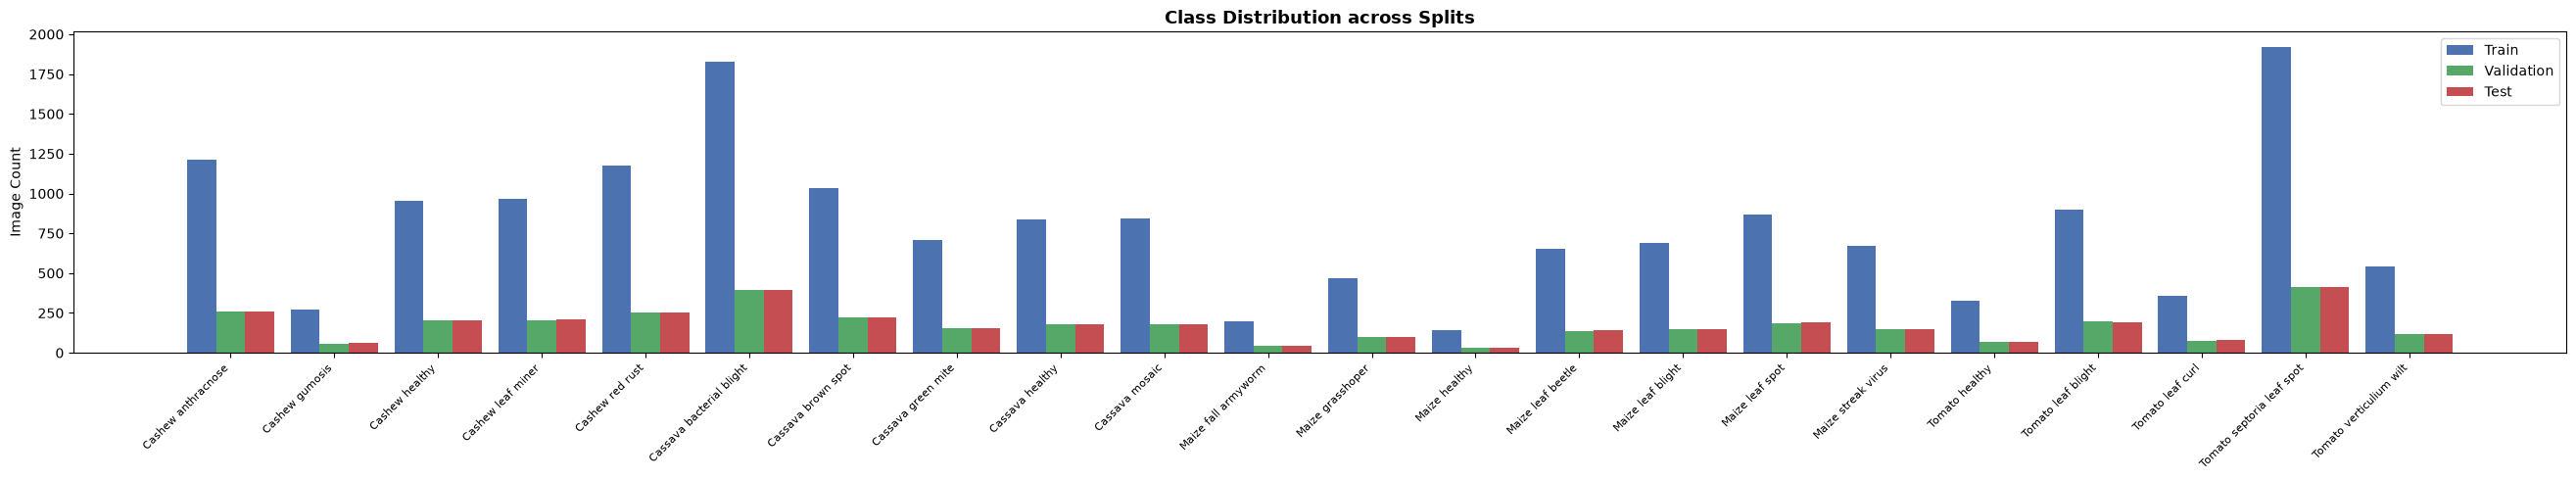

In [10]:
def count_classes(directory, class_names):
    return [len(os.listdir(os.path.join(directory, c))) for c in class_names]

train_counts = count_classes(TRAIN_DIR, CLASS_NAMES)
val_counts   = count_classes(VAL_DIR,   CLASS_NAMES)
test_counts  = count_classes(TEST_DIR,  CLASS_NAMES)

x = np.arange(NUM_CLASSES)
w = 0.28
fig, ax = plt.subplots(figsize=(max(12, NUM_CLASSES * 1.2), 5))
ax.bar(x - w, train_counts, w, label="Train",      color="#4C72B0")
ax.bar(x,     val_counts,   w, label="Validation",  color="#55A868")
ax.bar(x + w, test_counts,  w, label="Test",        color="#C44E52")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_title("Class Distribution across Splits", fontsize=13, fontweight="bold")
ax.set_ylabel("Image Count"); ax.legend()
plt.tight_layout(); plt.show()

### DIP: Geometric and Intensity Transformations

Data augmentation applies digital image processing transformations to synthetic training images, expanding effective dataset variance and enforcing invariance to camera orientation and field illumination.

#### Important: VGG16 Augmentation Pipeline Configuration
Unlike the other model notebooks in this project, **VGG16 uses a specialized, conservative augmentation pipeline**:
1. **Geometric Transformations:**
   - **Horizontal Flipping Only:** `RandomFlip("horizontal")` reflects pixels across the vertical axis. Vertical flip is intentionally omitted to prevent unnatural leaf vein orientations.
   - **Rotation:** `RandomRotation(0.20)` applies 2D affine rotation. In Keras, a factor of **$0.20$ represents a fraction of $2\pi$**, meaning images are randomly rotated within $[-0.20 \times 360^\circ, +0.20 \times 360^\circ] = [-72^\circ, +72^\circ]$, **not** 20 degrees.
   - **Scaling (Zoom):** `RandomZoom(0.15)` scales coordinates by $\pm 15\%$, simulating variable camera distances.
2. **Intensity Transformations:**
   - **Contrast Adjustment:** `RandomContrast(0.10)` adjusts dynamic range by $\pm 10\%$.
   - **Note:** `RandomBrightness` is **not included** in VGG16's augmentation sequence, preserving natural luminance levels for VGG16's sensitive dense classification head.

### CELL 7 ── Data Augmentation


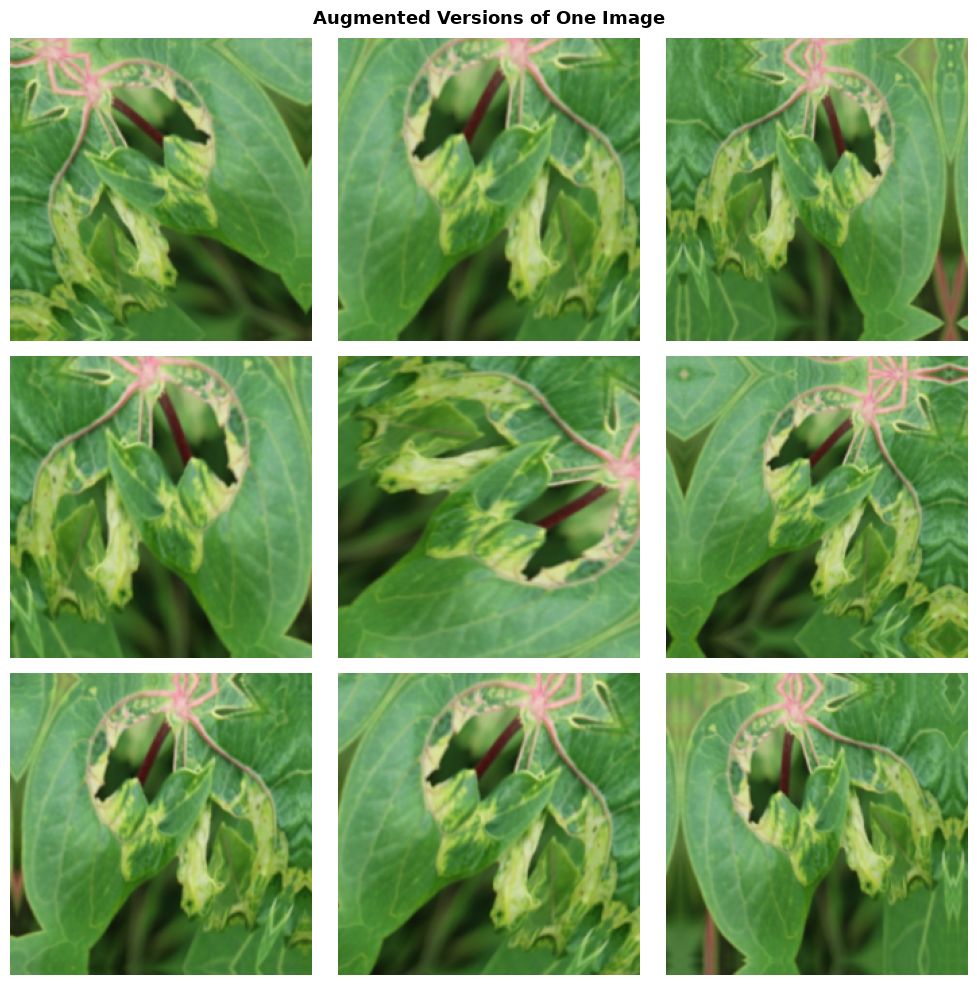

In [11]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.20),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.10),
], name="augmentation")

for images, _ in train_ds.take(1):
    sample = images[0]
aug_samples = [data_augmentation(tf.expand_dims(sample, 0))[0] for _ in range(9)]

plt.figure(figsize=(10, 10))
plt.suptitle("Augmented Versions of One Image", fontsize=13, fontweight="bold")
for i, img in enumerate(aug_samples):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img.numpy().astype("uint8")); plt.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# DIP VISUALIZATION: Individual Geometric and Intensity Transformations Applied Separately
# We visualize only the transformations actually configured in VGG16's pipeline
for images, _ in train_ds.take(1):
    base_sample = images[0]
    break

t_flip = layers.RandomFlip("horizontal", seed=42)
t_rot  = layers.RandomRotation(0.20, seed=42)            # +/- 72 degrees
t_zoom = layers.RandomZoom(0.15, seed=42)                # +/- 15% zoom
t_cont = layers.RandomContrast(0.10, seed=42)            # +/- 10% contrast

sample_tensor = tf.expand_dims(base_sample, 0)

transforms_list = [
    ("Original", base_sample.numpy().astype("uint8"), "No transformation (Reference)"),
    ("Horizontal Flip", t_flip(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Left-right spatial reflection"),
    ("Rotation (±72°)", t_rot(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Coordinate rotation around center"),
    ("Zoom Scaling", t_zoom(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Spatial scaling (zoom in/out)"),
    ("Contrast Shift", t_cont(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Dynamic range stretching (±10%)"),
]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
fig.suptitle("DIP: Isolated Transformations Supported in VGG16 Pipeline", fontsize=14, fontweight="bold")

for ax, (title, img_trans, desc) in zip(axes, transforms_list):
    ax.imshow(img_trans)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(desc, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

### DIP: Convolutional Filtering and Hierarchical Feature Extraction

#### Mathematical Formulation of 2D Spatial Convolution
In discrete 2D digital image processing, spatial filtering correlates an input feature map $X$ with a 2D filter kernel $K$ of spatial dimensions $M \times N$:

$$Y(i, j) = (X * K)(i, j) = \sum_{m=-M/2}^{M/2} \sum_{n=-N/2}^{N/2} K(m, n) \cdot X(i + m, j + n)$$

#### VGG16: Stacked Convolution Blocks and Spatial Feature Hierarchy
VGG16 consists of 13 convolutional layers arranged into 5 blocks followed by max-pooling layers:
- **Block 1 (2 layers, 64 filters of $3 \times 3$):** Receptive field of $5 \times 5$. Extracts low-level spatial primitives: high-contrast leaf edges, primary vein boundaries, and color transitions.
- **Block 2 (2 layers, 128 filters of $3 \times 3$):** Receptive field of $14 \times 14$. Captures structural vein bifurcations, localized color gradients, and leaf contour curvatures.
- **Block 3 (3 layers, 256 filters of $3 \times 3$):** Receptive field of $40 \times 40$. Detects textural primitives: circular fungal spots, necrotic halos, and powdery patches.
- **Blocks 4 & 5 (3 layers each, 512 filters of $3 \times 3$):** Large receptive fields ($>100 \times 100$). Synthesize complex, high-level disease phenotypes: leaf blight progression, mosaic patterns, and severe pest damage.
- **Dense Classification Head:** Unlike models using Global Average Pooling, VGG16 flattens spatial feature maps (`layers.Flatten()`) into a high-dimensional vector connected to Dense layers, retaining spatial configuration at the expense of parameter volume.

---

### DIP: Pixel Intensity Preprocessing

| Model | Preprocessing Function | Expected Pixel Scale | Transformations Applied |
|---|---|---|---|
| **VGG16** | `tf.keras.applications.vgg16.preprocess_input` | $[0, 255]$ raw uint8/float32 | 1. RGB $\to$ BGR channel permutation<br>2. ImageNet mean subtraction: $[-103.939, -116.779, -123.68]$ |

#### Preprocessing Mechanism:
VGG16 standardizes input tensors by:
1. Reordering color channels from RGB to **BGR** to match the original VGG team's Caffe implementation.
2. Centering pixel intensities by subtracting the ImageNet mean channel values without scaling to $[0, 1]$:
   $$B' = B - 103.939, \quad G' = G - 116.779, \quad R' = R - 123.68$$
This centers data symmetrically around zero, accelerating backpropagation convergence.

### CELL 8 ── Build VGG16 Transfer Learning Model


In [12]:
base_model = VGG16(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False  # Freeze all convolutional blocks

inputs  = tf.keras.Input(shape=IMG_SIZE + (3,))
x       = data_augmentation(inputs)
x       = preprocess_input(x)     # VGG16: BGR mean subtraction
x       = base_model(x, training=False)
x       = layers.Flatten()(x)     # VGG16 uses Flatten, not GlobalAvgPool
x       = layers.Dense(512, activation="relu",
                        kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x       = layers.Dropout(0.50)(x)
x       = layers.Dense(256, activation="relu")(x)
x       = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="VGG16_CropDisease")
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 59s 1us/step


Model: "VGG16_CropDisease"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ augmentation[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │ 12,845,568 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    131,328 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 22)        │      5,654 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 27,697,238 (105.66 MB)

 Trainable params: 12,982,550 (49.52 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

### DIP: Visualizing Pretrained Convolutional Feature Maps

Below, we pass a sample test image through the pretrained VGG16 backbone to inspect the activation feature maps produced by its very first convolutional layer (`block1_conv1`).

In [ ]:
# DIP VISUALIZATION: Pretrained VGG16 First Convolutional Layer Feature Maps
try:
    # Target the very first conv layer of VGG16 (block1_conv1)
    first_conv_layer = base_model.get_layer("block1_conv1")
    feat_extractor = tf.keras.Model(inputs=base_model.input, outputs=first_conv_layer.output)
    
    for test_imgs, test_lbls in test_ds.take(1):
        sample_img = test_imgs[0:1] # shape (1, 224, 224, 3)
        sample_lbl = test_lbls[0].numpy()
        break
        
    preproc_sample = preprocess_input(tf.cast(sample_img, tf.float32))
    feat_maps = feat_extractor.predict(preproc_sample, verbose=0)
    # feat_maps shape: (1, 224, 224, 64)
    
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle(f"DIP Activation Maps: VGG16 First Conv Layer (block1_conv1) — {CLASS_NAMES[sample_lbl]}", fontsize=14, fontweight="bold")
    
    axes[0, 0].imshow(sample_img[0].numpy().astype("uint8"))
    axes[0, 0].set_title("Input Image", fontsize=10, fontweight="bold")
    axes[0, 0].axis("off")
    
    for idx in range(1, 10):
        r, c = divmod(idx, 5)
        fmap = feat_maps[0, :, :, idx - 1]
        axes[r, c].imshow(fmap, cmap="viridis")
        axes[r, c].set_title(f"Filter #{idx} Response", fontsize=10)
        axes[r, c].axis("off")
        
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Feature map visualization skipped: {e}")

### Digital Image Processing vs. Machine Learning in Model Training

- **Image Processing Operations:** Resizing to $224 \times 224$, geometric coordinate transforms (horizontal flip, rotation, zoom), RGB to BGR channel reordering, ImageNet mean centering, 2D stacked spatial convolutions, and max-pooling downsampling.
- **Machine Learning Operations:** Categorical cross-entropy loss computation, error backpropagation, Adam optimizer weight updates, learning rate reduction on plateaus, transfer learning backbone freezing (Phase 1), and unfreezing the final convolutional block (`block5`) for fine-tuning (Phase 2).

DIP structures the optical signals into informative spatial feature representations; ML discovers the optimal weighting parameters across those representations.

### CELL 9 ── Compile & Train Phase 1 (frozen backbone)


In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cb_early = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                   restore_best_weights=True, verbose=1)
cb_lr    = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.4,
                                       patience=2, min_lr=1e-7, verbose=1)
cb_ckpt  = callbacks.ModelCheckpoint("best_vgg16.keras", save_best_only=True,
                                      monitor="val_accuracy", verbose=1)

history = model.fit(
    train_ds, epochs=EPOCHS, validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt], verbose=1)
print("Phase-1 training complete.")

Epoch 1/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2639 - loss: 3.6510
Epoch 1: val_accuracy improved from None to 0.38181, saving model to best_vgg16.h5



Epoch 1: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1836s 2s/step - accuracy: 0.2639 - loss: 3.6510 - val_accuracy: 0.3818 - val_loss: 2.2652 - learning_rate: 0.0010
Epoch 2/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2789 - loss: 2.7115
Epoch 2: val_accuracy improved from 0.38181 to 0.38367, saving model to best_vgg16.h5



Epoch 2: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1588s 1s/step - accuracy: 0.2789 - loss: 2.7115 - val_accuracy: 0.3837 - val_loss: 2.2893 - learning_rate: 0.0010
Epoch 3/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2879 - loss: 2.6774
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0004000000189989805.

Epoch 3: val_accuracy did not improve from 0.38367
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1667s 2s/step - accuracy: 0.2879 - loss: 2.6774 - val_accuracy: 0.3696 - val_loss: 2.3698 - learning_rate: 0.0010
Epoch 4/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3160 - loss: 2.5072
Epoch 4: val_accuracy improved from 0.38367 to 0.46450, saving model to best_vgg16.h5



Epoch 4: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1789s 2s/step - accuracy: 0.3160 - loss: 2.5072 - val_accuracy: 0.4645 - val_loss: 2.1172 - learning_rate: 4.0000e-04
Epoch 5/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3348 - loss: 2.4358
Epoch 5: val_accuracy improved from 0.46450 to 0.51210, saving model to best_vgg16.h5



Epoch 5: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2043s 2s/step - accuracy: 0.3348 - loss: 2.4358 - val_accuracy: 0.5121 - val_loss: 1.8745 - learning_rate: 4.0000e-04
Epoch 6/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3829 - loss: 2.2724
Epoch 6: val_accuracy improved from 0.51210 to 0.53443, saving model to best_vgg16.h5


...


Epoch 18: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1802s 2s/step - accuracy: 0.5962 - loss: 1.3729 - val_accuracy: 0.6993 - val_loss: 1.0673 - learning_rate: 4.0000e-04
Epoch 19/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6014 - loss: 1.3550
Epoch 19: val_accuracy improved from 0.69928 to 0.70779, saving model to best_vgg16.h5



Epoch 19: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1653s 2s/step - accuracy: 0.6014 - loss: 1.3550 - val_accuracy: 0.7078 - val_loss: 1.0275 - learning_rate: 4.0000e-04
Epoch 20/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 14s/step - accuracy: 0.6063 - loss: 1.3336 
Epoch 20: val_accuracy did not improve from 0.70779
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 16010s 15s/step - accuracy: 0.6063 - loss: 1.3336 - val_accuracy: 0.6982 - val_loss: 1.0353 - learning_rate: 4.0000e-04
Epoch 21/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6108 - loss: 1.3358
Epoch 21: ReduceLROnPlateau reducing learning rate to 0.00016000000759959222.

Epoch 21: val_accuracy did not improve from 0.70779
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1512s 1s/step - accuracy: 0.6108 - loss: 1.3358 - val_accuracy: 0.7065 - val_loss: 1.0291 - learning_rate: 4.0000e-04
Epoch 22/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 44s/step - accuracy: 0.6239 - loss: 1.2555 
Epoch 22: val_accuracy improved from 0.70779 to 0.


Epoch 22: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 49102s 45s/step - accuracy: 0.6239 - loss: 1.2555 - val_accuracy: 0.7174 - val_loss: 0.9843 - learning_rate: 1.6000e-04
Epoch 23/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6388 - loss: 1.2188
Epoch 23: val_accuracy did not improve from 0.71736
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1993s 2s/step - accuracy: 0.6388 - loss: 1.2188 - val_accuracy: 0.7123 - val_loss: 0.9917 - learning_rate: 1.6000e-04
Epoch 24/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6341 - loss: 1.2143
Epoch 24: val_accuracy improved from 0.71736 to 0.72188, saving model to best_vgg16.h5



Epoch 24: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2053s 2s/step - accuracy: 0.6341 - loss: 1.2143 - val_accuracy: 0.7219 - val_loss: 0.9555 - learning_rate: 1.6000e-04
Epoch 25/25
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6408 - loss: 1.1880
Epoch 25: val_accuracy improved from 0.72188 to 0.72481, saving model to best_vgg16.h5



Epoch 25: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 1868s 2s/step - accuracy: 0.6408 - loss: 1.1880 - val_accuracy: 0.7248 - val_loss: 0.9557 - learning_rate: 1.6000e-04
Restoring model weights from the end of the best epoch: 24.
Phase-1 training complete.


### CELL 10 ── Fine-Tuning Phase 2 (unfreeze last conv block: block5)


In [14]:
# Unfreeze the last convolutional block of VGG16 (block5_conv1/2/3)
base_model.trainable = True
for layer in base_model.layers:
    if "block5" not in layer.name:
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_ft = model.fit(
    train_ds, epochs=10, validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt], verbose=1)
print("Fine-tuning complete.")

for k in history.history:
    history.history[k] += history_ft.history.get(k, [])

Epoch 1/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6444 - loss: 1.1879
Epoch 1: val_accuracy improved from 0.72481 to 0.73358, saving model to best_vgg16.h5



Epoch 1: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2029s 2s/step - accuracy: 0.6444 - loss: 1.1879 - val_accuracy: 0.7336 - val_loss: 0.9192 - learning_rate: 1.0000e-05
Epoch 2/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6557 - loss: 1.1279
Epoch 2: val_accuracy did not improve from 0.73358
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2354s 2s/step - accuracy: 0.6557 - loss: 1.1279 - val_accuracy: 0.7211 - val_loss: 0.9194 - learning_rate: 1.0000e-05
Epoch 3/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6570 - loss: 1.1155
Epoch 3: val_accuracy improved from 0.73358 to 0.73651, saving model to best_vgg16.h5



Epoch 3: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2370s 2s/step - accuracy: 0.6570 - loss: 1.1155 - val_accuracy: 0.7365 - val_loss: 0.8895 - learning_rate: 1.0000e-05
Epoch 4/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6766 - loss: 1.0700
Epoch 4: val_accuracy improved from 0.73651 to 0.74528, saving model to best_vgg16.h5



Epoch 4: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2386s 2s/step - accuracy: 0.6766 - loss: 1.0700 - val_accuracy: 0.7453 - val_loss: 0.8448 - learning_rate: 1.0000e-05
Epoch 5/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6810 - loss: 1.0425
Epoch 5: val_accuracy improved from 0.74528 to 0.75219, saving model to best_vgg16.h5



Epoch 5: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2423s 2s/step - accuracy: 0.6810 - loss: 1.0425 - val_accuracy: 0.7522 - val_loss: 0.8369 - learning_rate: 1.0000e-05
Epoch 6/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6879 - loss: 1.0259
Epoch 6: val_accuracy improved from 0.75219 to 0.75459, saving model to best_vgg16.h5



Epoch 6: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2299s 2s/step - accuracy: 0.6879 - loss: 1.0259 - val_accuracy: 0.7546 - val_loss: 0.8341 - learning_rate: 1.0000e-05
Epoch 7/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6977 - loss: 0.9848
Epoch 7: val_accuracy did not improve from 0.75459
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2650s 2s/step - accuracy: 0.6977 - loss: 0.9848 - val_accuracy: 0.7541 - val_loss: 0.8190 - learning_rate: 1.0000e-05
Epoch 8/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7038 - loss: 0.9693
Epoch 8: val_accuracy improved from 0.75459 to 0.76309, saving model to best_vgg16.h5



Epoch 8: finished saving model to best_vgg16.h5
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2711s 2s/step - accuracy: 0.7038 - loss: 0.9693 - val_accuracy: 0.7631 - val_loss: 0.8160 - learning_rate: 1.0000e-05
Epoch 9/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7088 - loss: 0.9594
Epoch 9: val_accuracy did not improve from 0.76309
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2696s 2s/step - accuracy: 0.7088 - loss: 0.9594 - val_accuracy: 0.7269 - val_loss: 0.9669 - learning_rate: 1.0000e-05
Epoch 10/10
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7140 - loss: 0.9383
Epoch 10: val_accuracy did not improve from 0.76309
1098/1098 ━━━━━━━━━━━━━━━━━━━━ 2705s 2s/step - accuracy: 0.7140 - loss: 0.9383 - val_accuracy: 0.7615 - val_loss: 0.8118 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 10.
Fine-tuning complete.


### CELL 11 ── Training Curves


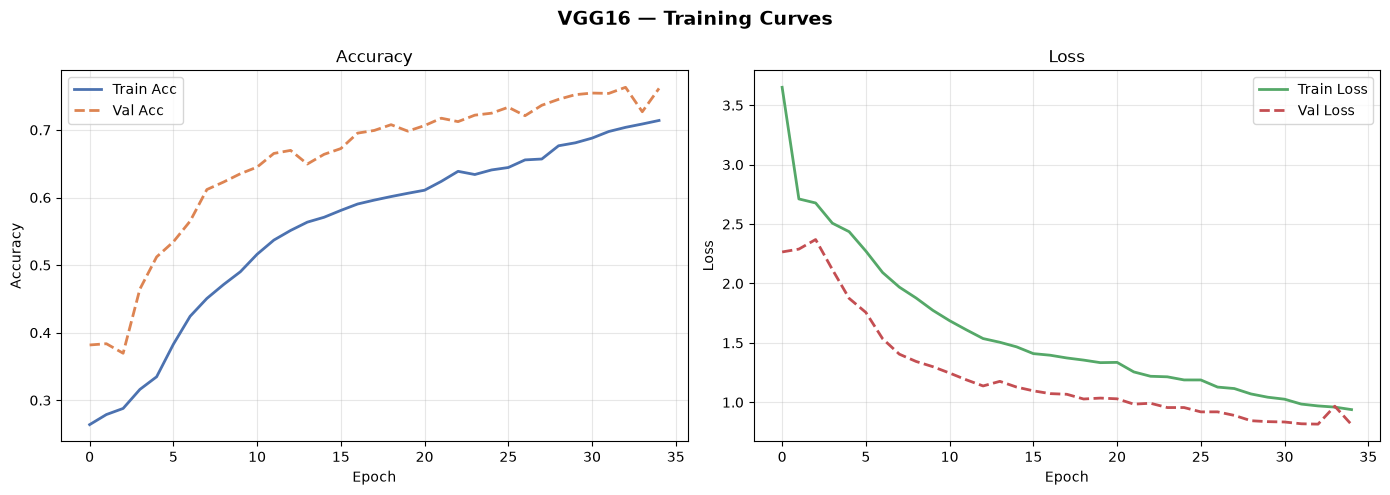

In [15]:
acc      = history.history["accuracy"]
val_acc  = history.history["val_accuracy"]
loss     = history.history["loss"]
val_loss = history.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("VGG16 — Training Curves", fontsize=14, fontweight="bold")

axes[0].plot(acc,     label="Train Acc",  linewidth=2, color="#4C72B0")
axes[0].plot(val_acc, label="Val Acc",    linewidth=2, color="#DD8452", linestyle="--")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(loss,     label="Train Loss", linewidth=2, color="#55A868")
axes[1].plot(val_loss, label="Val Loss",   linewidth=2, color="#C44E52", linestyle="--")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

### CELL 12 ── Evaluate on Test Set


In [16]:
model.load_weights("best_vgg16.keras")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy : {test_acc  * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

238/238 ━━━━━━━━━━━━━━━━━━━━ 296s 1s/step - accuracy: 0.7713 - loss: 0.7993

Test Accuracy : 77.13%
Test Loss     : 0.7993


### CELL 13 ── Confusion Matrix & Classification Report



Classification Report:
                           precision    recall  f1-score   support

       Cashew anthracnose     0.8852    0.8308    0.8571       260
           Cashew gumosis     0.9833    0.9833    0.9833        60
           Cashew healthy     0.9174    0.9709    0.9434       206
        Cashew leaf miner     0.9162    0.8413    0.8772       208
          Cashew red rust     0.9579    0.9881    0.9728       253
 Cassava bacterial blight     0.7943    0.9237    0.8541       393
       Cassava brown spot     0.8600    0.7713    0.8132       223
       Cassava green mite     0.8438    0.8824    0.8626       153
          Cassava healthy     0.9144    0.9500    0.9319       180
           Cassava mosaic     0.8506    0.8132    0.8315       182
      Maize fall armyworm     1.0000    0.6136    0.7606        44
         Maize grasshoper     0.9394    0.9118    0.9254       102
            Maize healthy     0.7105    0.8438    0.7714        32
        Maize leaf beetle     0.9706 

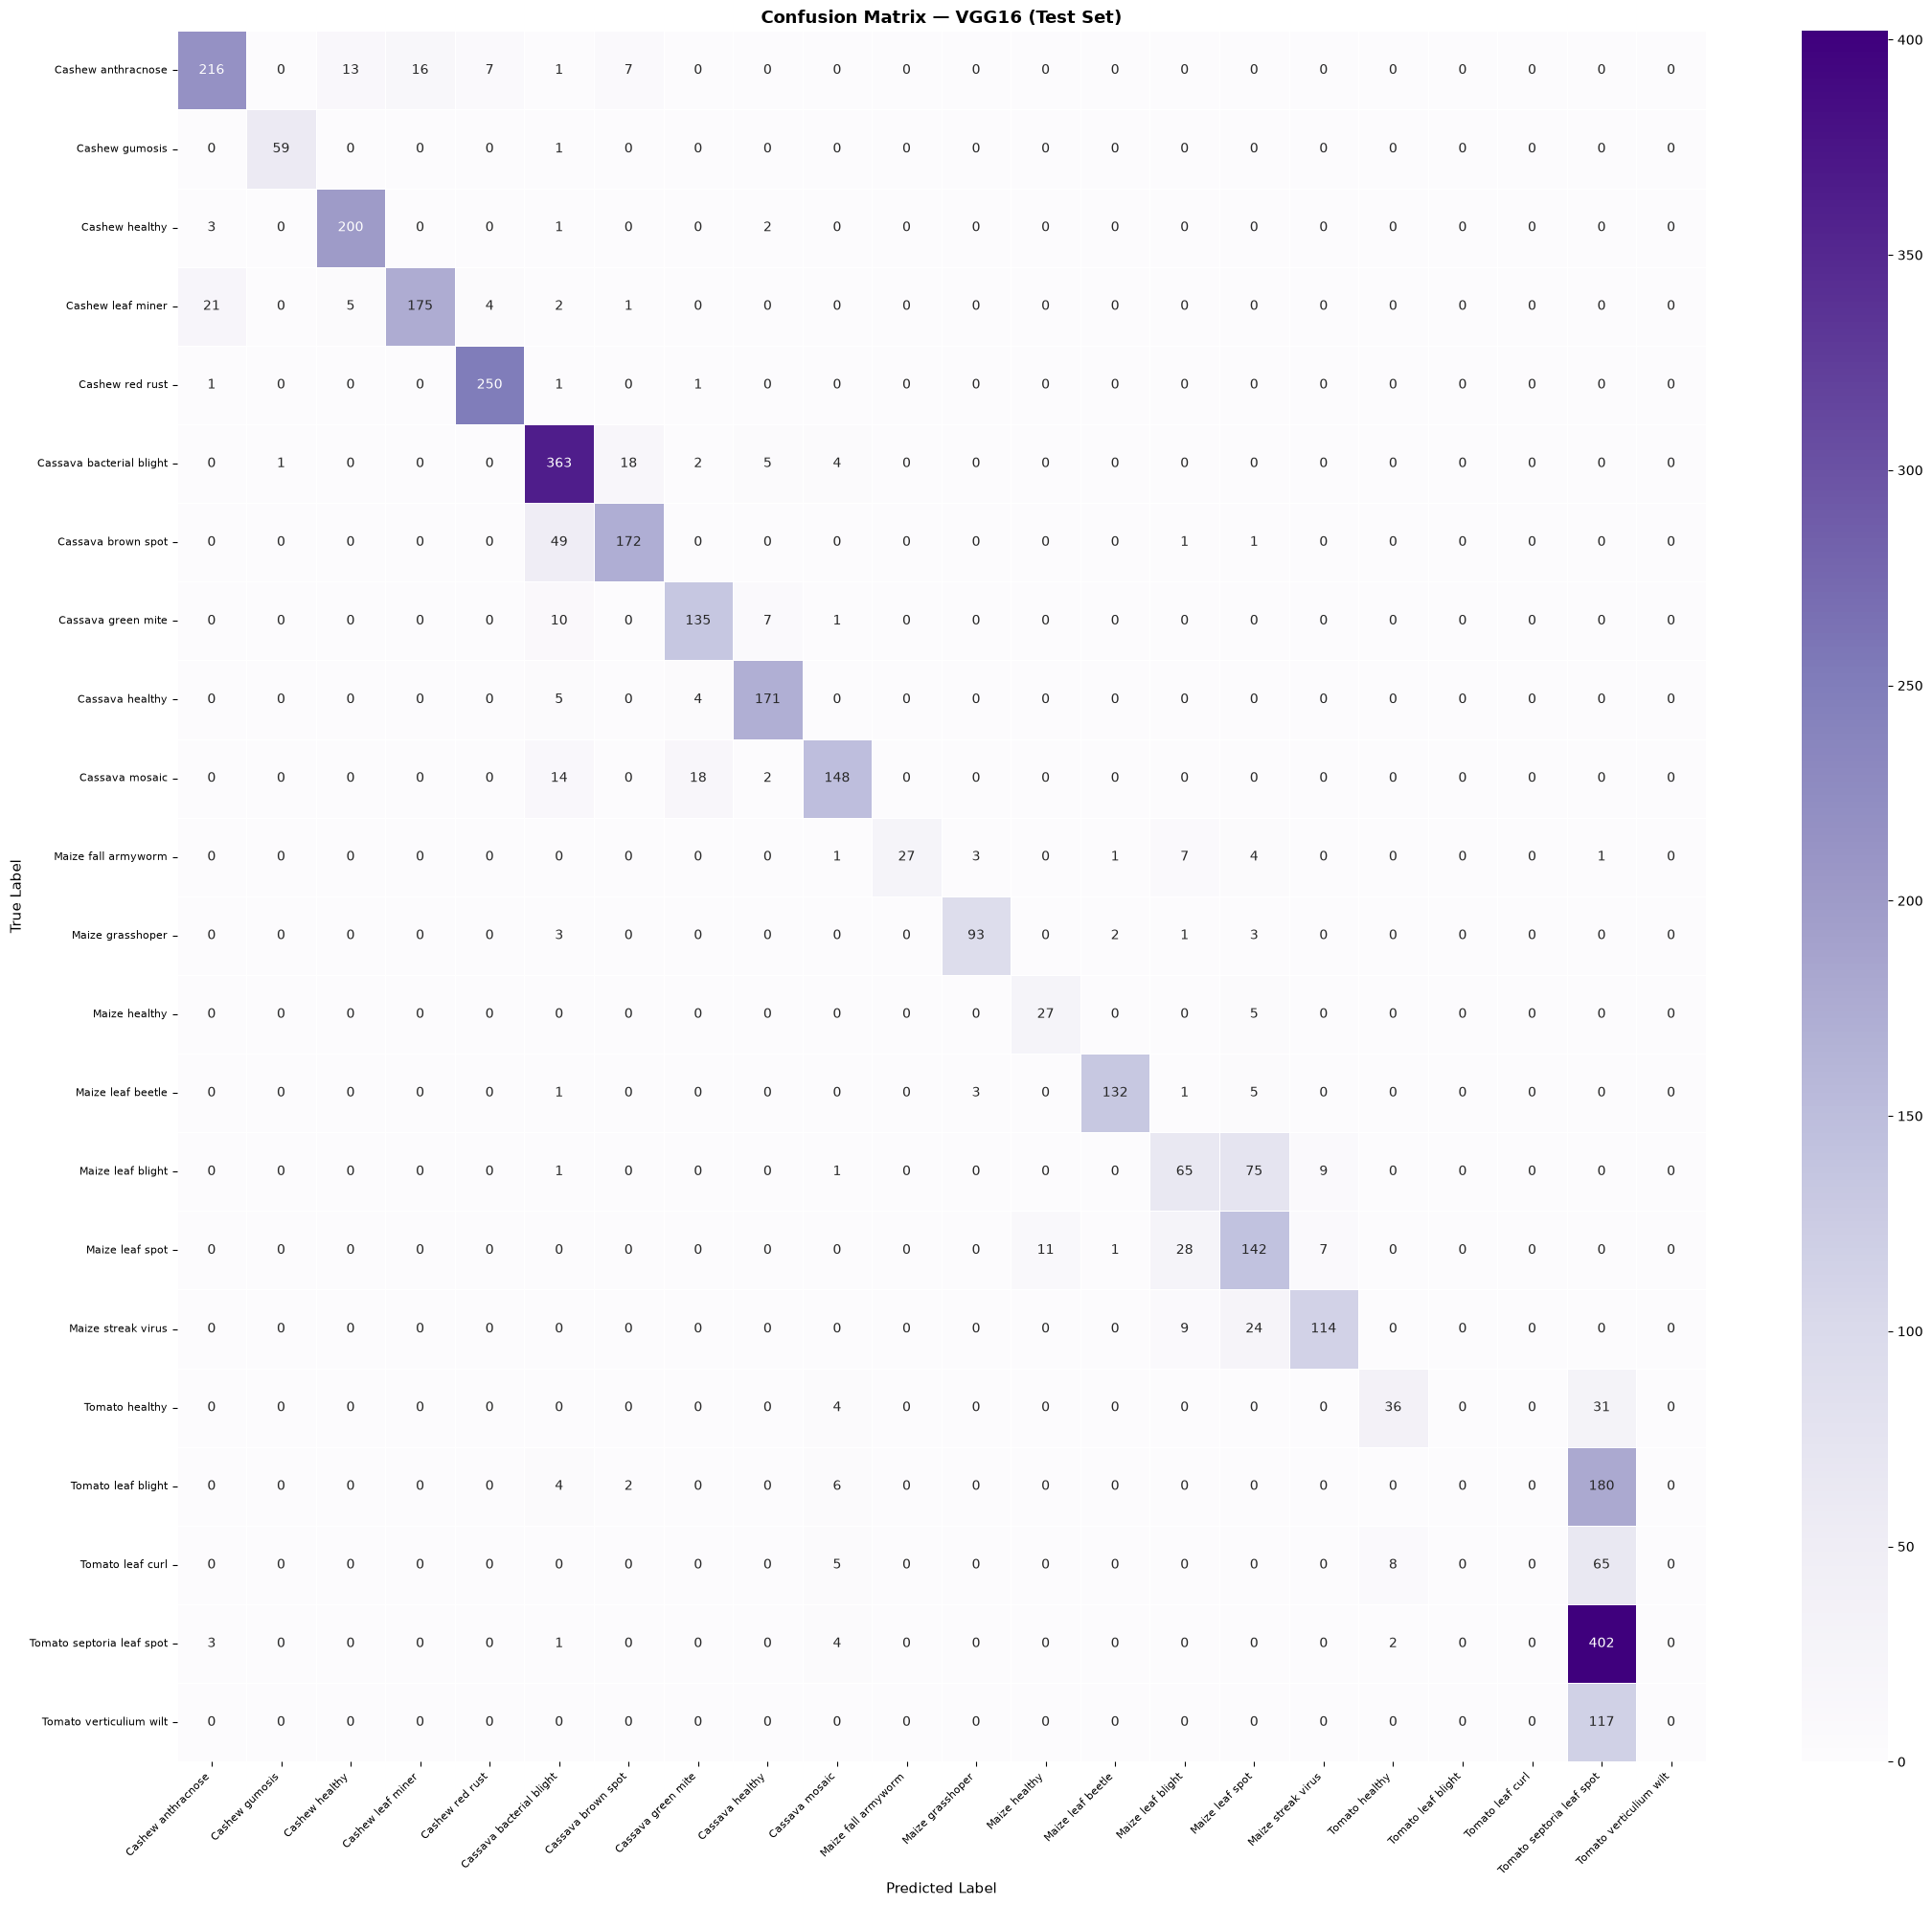

In [17]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(12, NUM_CLASSES), max(10, NUM_CLASSES - 2)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
plt.title("Confusion Matrix — VGG16 (Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11); plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout(); plt.show()

### CELL 14 ── Per-Class Accuracy Bar Chart


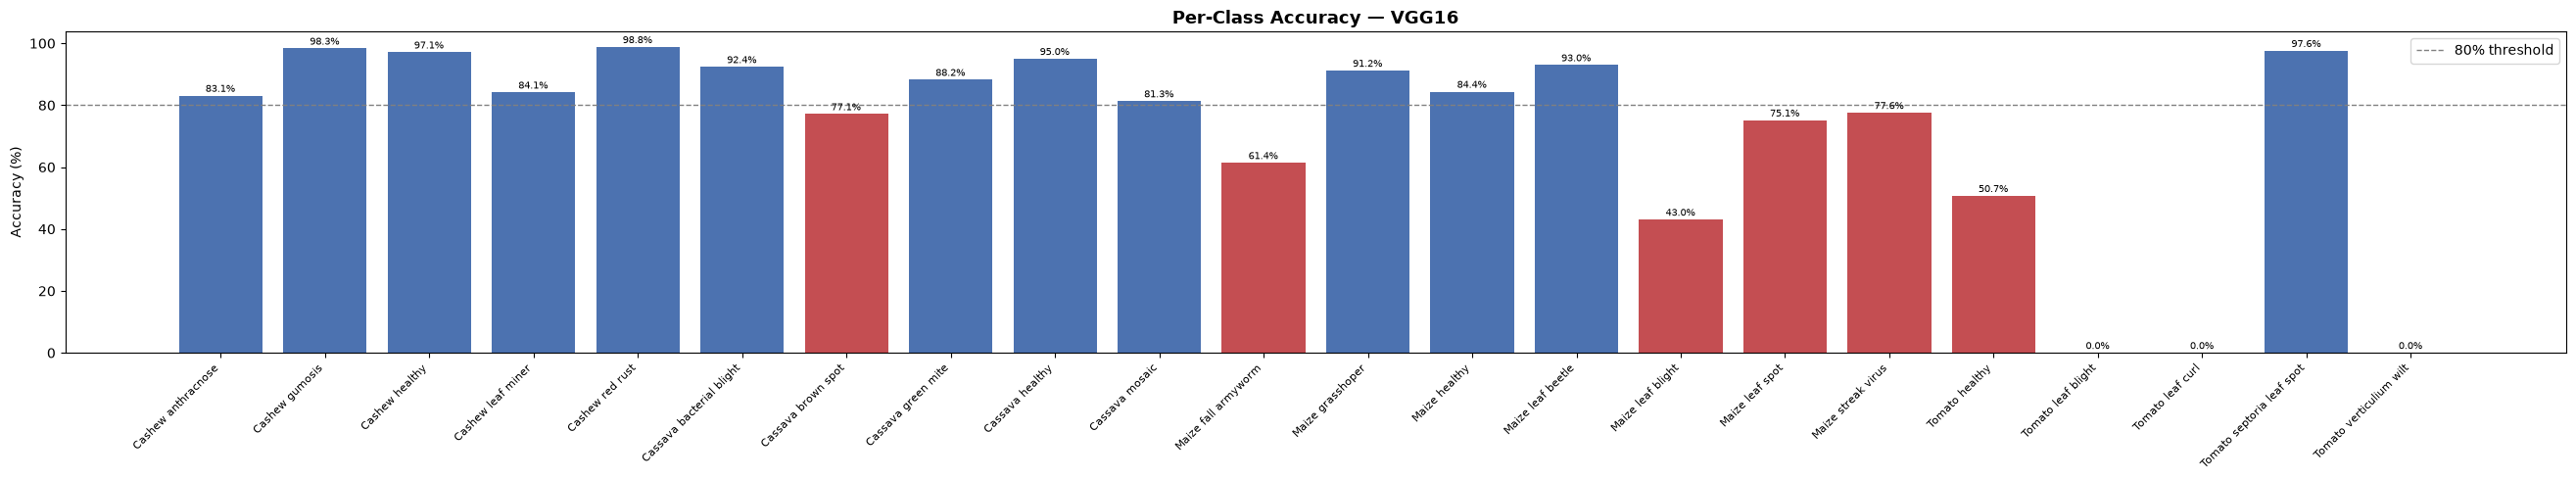

In [18]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(max(12, NUM_CLASSES * 1.2), 5))
colors = ["#4C72B0" if a >= 0.8 else "#C44E52" for a in per_class_acc]
bars = plt.bar(CLASS_NAMES, per_class_acc * 100, color=colors)
plt.axhline(y=80, color="grey", linestyle="--", linewidth=1, label="80% threshold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.ylabel("Accuracy (%)"); plt.title("Per-Class Accuracy — VGG16", fontsize=13, fontweight="bold")
plt.legend()
for bar, acc_val in zip(bars, per_class_acc):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{acc_val*100:.1f}%", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.show()

### CELL 15 ── Sample Predictions Grid (Green = Correct, Red = Wrong)


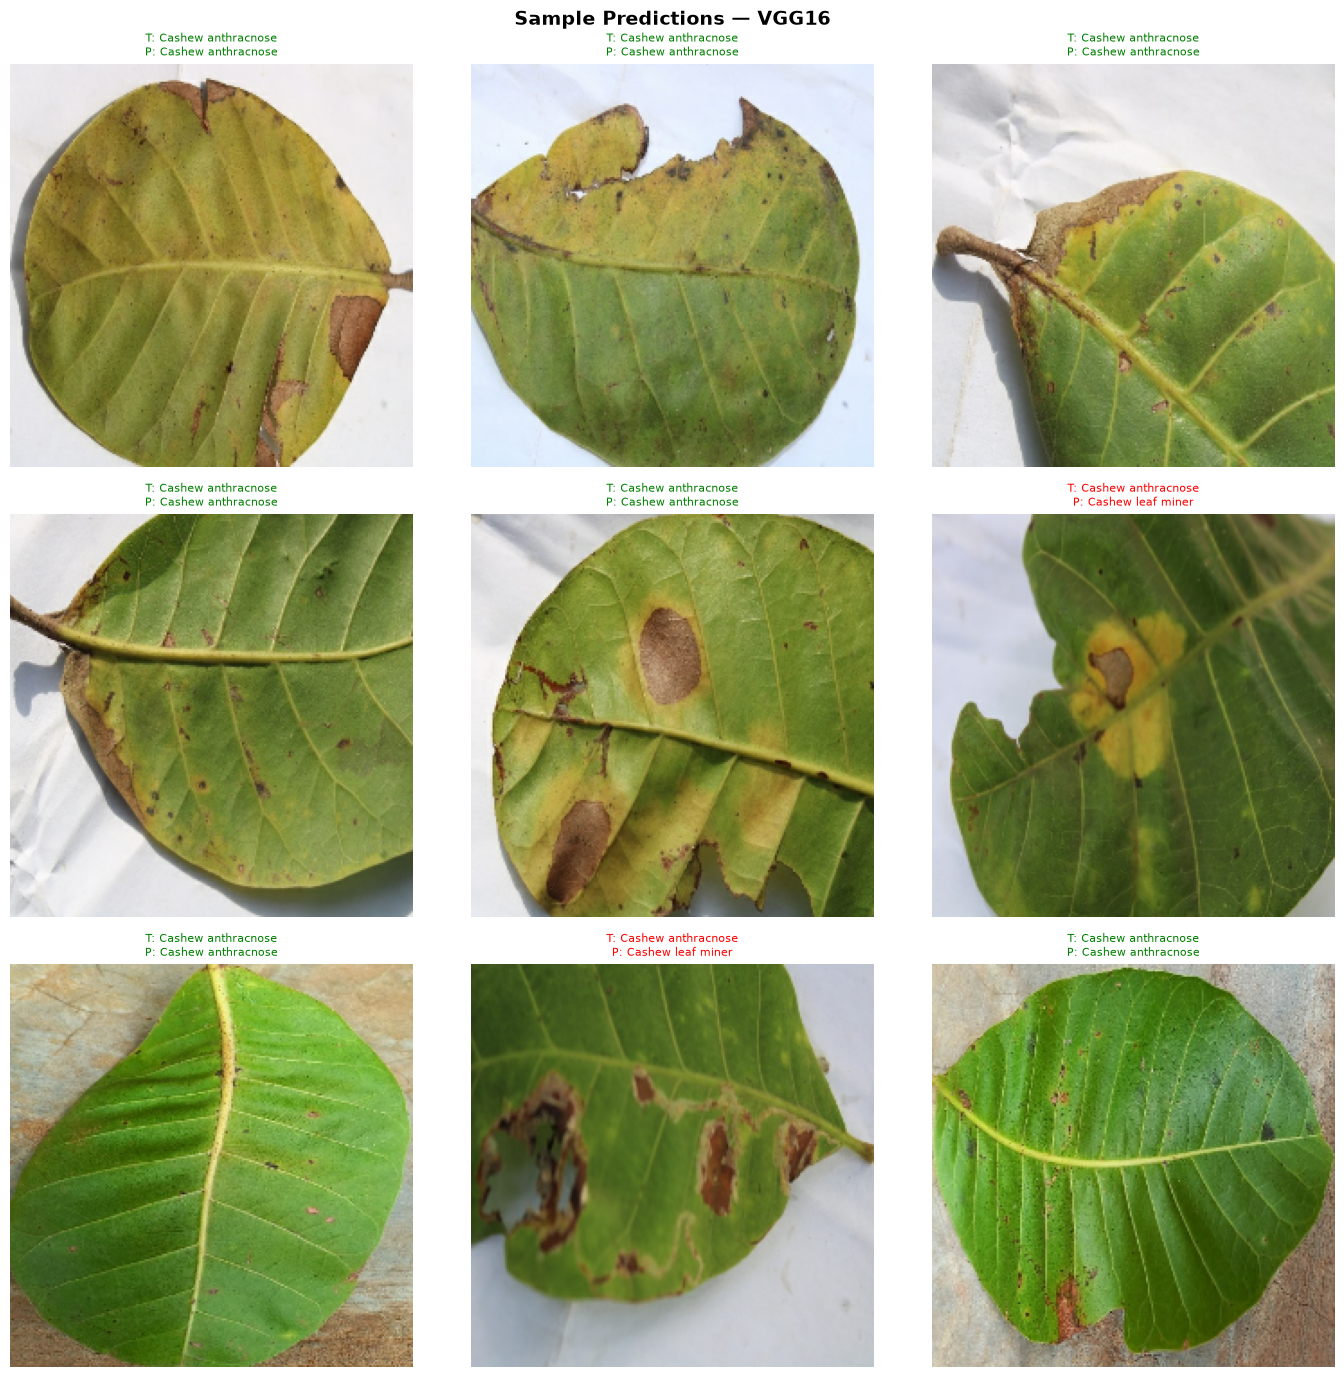

In [19]:
plt.figure(figsize=(14, 14))
plt.suptitle("Sample Predictions — VGG16", fontsize=14, fontweight="bold")
for images, labels in test_ds.take(1):
    preds = np.argmax(model.predict(images, verbose=0), axis=1)
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_lbl = CLASS_NAMES[labels[i]]
        pred_lbl = CLASS_NAMES[preds[i]]
        colour   = "green" if true_lbl == pred_lbl else "red"
        plt.title(f"T: {true_lbl}\nP: {pred_lbl}", color=colour, fontsize=8)
        plt.axis("off")
plt.tight_layout(); plt.show()

### Interpretation of Image-Based Classification Results

In evaluating the sample prediction grid and confusion matrix from a digital image processing perspective:

1. **Visual Cues Leveraged by the Classifier:**
   - **Chromatic Discoloration:** Chlorotic margins and dark necrotic lesions serve as primary chromatic markers.
   - **Spatial Texture:** Powdery mildew, serpentine leaf miner tracks, and fungal spots provide distinct spatial frequency signatures.
2. **Sources of Inter-Class Confusion:**
   - **Morphological Similarity:** Early blight and leaf spots produce similar circular necrotic lesions.
   - **Environmental Artifacts:** Harsh daylight glares and deep foliage shadows can distort color and contrast.
   - **Complex Backgrounds:** Soil backgrounds and overlapping non-target vegetation introduce spurious edge responses.
3. **Academic Clarification on Evaluation vs. DIP:**
   - A **confusion matrix** evaluates categorical classification performance, not digital image processing.
   - A **whole-image classification label** indicates the diagnosis of the overall image tile; it does **not** generate pixel-level lesion boundary masks.
   - **Activation maps** show filter responses across spatial receptive fields; they do **not** constitute semantic segmentation masks.

### CELL 16 ── Save Final Model


In [20]:
model.save("VGG16_Crop_Disease_Final.h5")
print("Model saved →  VGG16_Crop_Disease_Final.h5")

Model saved →  VGG16_Crop_Disease_Final.h5


### Digital Image Processing Summary and Case Study Findings

#### 1. Input Image Representation and Dimensions
VGG16 processes standardized $224 \times 224 \times 3$ RGB digital images ($150,528$ pixel intensity values), decoded from JPEG files into numerical arrays.

#### 2. Image Transformations Applied
- **Geometric Transformations:** Horizontal spatial reflection, affine rotation ($\pm 72^\circ$), and zoom scaling ($\pm 15\%$) enforce rotational and scale invariance against camera positioning.
- **Intensity Transformations:** Contrast adjustment ($\pm 10\%$); brightness transforms are excluded to maintain natural illumination balance.

#### 3. Pixel Intensity Preprocessing
Input tensors undergo channel permutation from RGB to BGR, followed by ImageNet channel mean subtraction ($[-103.939, -116.779, -123.68]$) via `vgg16.preprocess_input`.

#### 4. Convolutional Feature Extraction
VGG16 utilizes stacked $3 \times 3$ spatial convolution filters across 5 hierarchical blocks, illustrating how small cascaded kernels enlarge spatial receptive fields while reducing parameter counts.

#### 5. Relevance to Crop Disease Identification
The homogeneous architecture provides deep spatial abstraction capable of recognizing disease lesions across various stages of infection.

#### 6. Limitations of the Image Processing Approach
- **No Explicit Lesion Segmentation:** Categorizes whole image tiles rather than segmenting individual lesion perimeters.
- **Downsampling:** Bilinear downsampling to $224 \times 224$ can suppress very fine micro-lesions.
- **Large Memory Footprint:** High parameter volume ($138\text{M}$ parameters) requires smaller batch sizes (`BATCH_SIZE = 16`) and substantial memory compared to lightweight mobile architectures.